# 07 — Audit phân bố split ViGoEmotions

Notebook cung cấp **bằng chứng thực nghiệm về chất lượng phân bố đa nhãn** của split đang dùng cho midterm. Giữ nguyên train/validation/test, không train mô hình, không tìm ngưỡng và không sửa CSV hoặc fixed split IDs.

**Không chứng minh thuật toán tạo split:** tỷ lệ/phân bố gần nhau không đủ để khẳng định đã dùng iterative multi-label stratification. Đây là audit dữ liệu được cấp, không phải mã chia lại tập.

Phạm vi: tỷ lệ split, tính toàn vẹn/leakage, prevalence của 27 cảm xúc + Neutral, cardinality theo hai cách mã hóa, Neutral-only/mixed và các cặp nhãn chọn từ train. Không tạo co-occurrence/correlation matrix từ test labels theo Reproducibility Rules của đề.

**Chạy:** mở từ project root hoặc `notebooks/`, chọn kernel `.venv` của project, Restart Kernel → Run All. Cần ba CSV được cấp quyền trong `data/`; dùng dependency của project. Không cần GPU/Internet. Kết quả chỉ chứa tổng hợp và ID, lưu riêng ở `reports/split_audit/`.

Nguồn yêu cầu: [đề ViGoEmotions, Midterm A và Reproducibility Rules](../docs/02-vigoemotions-vietnamese-emotion.pdf); [student guide](../docs/student-guide.pdf).

## 1. Giao thức cố định trước khi đọc kết quả

- Đọc ba split được cấp. Dùng đúng loader/normalization của pipeline: NFC + gom khoảng trắng; loại **bản train** có text trùng validation/test. Audit trước và sau loại overlap; không sửa dữ liệu nguồn.
- Kiểm tra thứ tự ID sau xử lý khớp `splits/*.csv`, split không giao ID, không giao text chuẩn hóa. Đây là các điều kiện toàn vẹn phải đạt.
- Đếm từng nhãn theo **tỷ lệ mẫu**, không so count thô giữa các split khác kích thước. Báo cáo chênh lệch điểm phần trăm và chênh lệch tương đối so với train.
- Giữ đủ IDs 0–26; Neutral là ID 27. Cardinality 27 không tính Neutral; cardinality 28 giữ nguyên annotation, kể cả mixed-neutral. Các nhóm Neutral-only/mixed/emotion-only loại trừ nhau.
- Phân bố dùng mô tả, **không đặt ngưỡng sau khi xem số liệu để gắn nhãn “đạt stratification”**. Cờ thiếu nhãn chỉ giúp phát hiện mất đại diện; không tự suy ra chất lượng tổng quát.
- Chọn 10 cặp cảm xúc từ train, hòa theo ID. Chỉ đối chiếu tỷ lệ cùng dương ở validation; không xây ma trận quan hệ nhãn test.
- Test labels chỉ dùng cho audit prevalence/cardinality như EDA, không dùng chọn model, threshold, cặp nhãn hoặc đổi split theo điểm mô hình.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import itertools
import json
import os
import platform
import sys
import unittest

os.environ.setdefault('MPLCONFIGDIR', '/tmp/vigo-matplotlib')
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p/'scripts/common.py').is_file() and (p/'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ project root hoặc notebooks/.')
sys.path.insert(0, str(ROOT/'scripts'))
from common import LABELS, load_data, normalize, parse_labels, targets

OUT = Path(os.environ.get('VIGO_SPLIT_AUDIT_OUTPUT', ROOT/'reports/split_audit')).resolve()
for protected in (ROOT/'data', ROOT/'splits', ROOT/'.git'):
    if OUT == protected.resolve() or protected.resolve() in OUT.parents:
        raise ValueError('Thư mục output không được nằm trong data/, splits/ hoặc .git/.')
OUT.mkdir(parents=True, exist_ok=True)
SPLITS = ('train', 'val', 'test')
LABELS28 = LABELS + ['neutral']
TOP_PAIRS = 10

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

protected_files = [ROOT/'data'/f'{s}.csv' for s in SPLITS]
protected_files += [ROOT/'splits'/f'{s}.csv' for s in (*SPLITS, 'excluded_train')]
protected_files = [p for p in protected_files if p.is_file()]
before_hashes = {str(p.relative_to(ROOT)): sha256(p) for p in protected_files}
print('Audit mô tả, không huấn luyện mô hình; output không chứa text nguồn.')

Audit mô tả, không huấn luyện mô hình; output không chứa text nguồn.


## 2. Hàm thống kê và kiểm tra bằng ví dụ biết trước

Các kiểm tra nhỏ dưới đây xác minh cách tính multi-hot, Neutral/mixed, cardinality, total variation và overlap chuẩn hóa; chúng không gán nhãn “đạt stratification” cho dữ liệu thật.

In [2]:
def targets28(frame):
    y = np.zeros((len(frame), 28), dtype=np.int64)
    for i, labels in enumerate(frame.label_ids):
        y[i, list(set(labels))] = 1
    return y

def cardinality_distribution(y, maximum):
    counts = np.bincount(y.sum(axis=1), minlength=maximum + 1)
    return counts / len(y)

def total_variation(a, b):
    return float(np.abs(np.asarray(a) - np.asarray(b)).sum() / 2)

def overlap_counts(left, right):
    common_text = set(left.normalized) & set(right.normalized)
    return dict(shared_ids=len(set(left.id) & set(right.id)),
                shared_normalized_texts=len(common_text),
                left_rows_with_shared_text=int(left.normalized.isin(common_text).sum()),
                right_rows_with_shared_text=int(right.normalized.isin(common_text).sum()))

def frequency_table(matrices):
    result = pd.DataFrame({'label_id': range(28), 'label': LABELS28})
    for split, y in matrices.items():
        result[f'{split}_count'] = y.sum(axis=0)
        result[f'{split}_prevalence'] = y.mean(axis=0)
    for split in ('val', 'test'):
        gap = result[f'{split}_prevalence'] - result.train_prevalence
        result[f'{split}_drift_pp'] = 100 * gap
        result[f'{split}_relative_drift_pct'] = 100 * gap / result.train_prevalence.replace(0, np.nan)
    return result

class AuditMathTests(unittest.TestCase):
    def test_neutral_mixed_and_repeated_labels(self):
        frame = pd.DataFrame({'label_ids': [[27], [2, 27], [2, 2]]})
        actual = targets28(frame)
        np.testing.assert_array_equal(actual.sum(axis=1), [1, 2, 1])
        np.testing.assert_array_equal(actual[:, :27].sum(axis=1), [0, 1, 1])
        np.testing.assert_array_equal(actual[:, 27], [1, 1, 0])

    def test_frequency_uses_proportions_not_split_size(self):
        train = np.zeros((4, 28), dtype=int); train[:2, 0] = 1
        val = np.zeros((2, 28), dtype=int); val[:1, 0] = 1
        table = frequency_table({'train': train, 'val': val, 'test': val})
        self.assertEqual(table.loc[0, 'val_drift_pp'], 0)
        val[:, 0] = 1
        shifted = frequency_table({'train': train, 'val': val, 'test': val})
        self.assertEqual(shifted.loc[0, 'val_drift_pp'], 50)

    def test_cardinality_and_total_variation(self):
        y = np.array([[0, 0], [1, 0], [1, 1], [1, 1]])
        np.testing.assert_allclose(cardinality_distribution(y, 2), [.25, .25, .5])
        self.assertEqual(total_variation([1, 0], [0, 1]), 1)
        self.assertEqual(total_variation([.25, .75], [.25, .75]), 0)

    def test_overlap_uses_pipeline_normalization(self):
        left = pd.DataFrame({'id': ['a'], 'normalized': [normalize('  rất   vui  ')]})
        right = pd.DataFrame({'id': ['b'], 'normalized': [normalize('rất vui')]})
        actual = overlap_counts(left, right)
        self.assertEqual(actual['shared_ids'], 0)
        self.assertEqual(actual['shared_normalized_texts'], 1)
        self.assertEqual(actual['left_rows_with_shared_text'], 1)

result = unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(AuditMathTests))
assert result.wasSuccessful(), 'Các phép kiểm tra số học phải qua trước khi audit dữ liệu thật.'

test_cardinality_and_total_variation (__main__.AuditMathTests.test_cardinality_and_total_variation) ... 

ok


test_frequency_uses_proportions_not_split_size (__main__.AuditMathTests.test_frequency_uses_proportions_not_split_size) ... 

ok


test_neutral_mixed_and_repeated_labels (__main__.AuditMathTests.test_neutral_mixed_and_repeated_labels) ... 

ok


test_overlap_uses_pipeline_normalization (__main__.AuditMathTests.test_overlap_uses_pipeline_normalization) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.062s

OK


## 3. Nạp dữ liệu và audit leakage trước/sau xử lý

Loader dừng khi schema, ID, labels hoặc văn bản rỗng không hợp lệ. `raw` tái dựng đúng tập hàng nguồn để đếm overlap; thứ tự raw train không dùng cho đối chiếu fixed IDs. Thứ tự effective train giữ đúng loader của các lượt đã chạy. Không hiển thị `text` hoặc `normalized`.

In [3]:
frames, excluded = load_data()
raw = dict(frames)
raw['train'] = pd.concat([frames['train'], excluded], ignore_index=True)
Y28 = {split: targets28(frame) for split, frame in frames.items()}
Y27 = {split: targets(frame) for split, frame in frames.items()}
for split in SPLITS:
    np.testing.assert_array_equal(Y28[split][:, :27], Y27[split])

leakage_rows = []
for stage, collection in [('raw', raw), ('effective', frames)]:
    for left, right in itertools.combinations(SPLITS, 2):
        leakage_rows.append(dict(stage=stage, left_split=left, right_split=right,
                                  **overlap_counts(collection[left], collection[right])))
leakage = pd.DataFrame(leakage_rows)
integrity_rows = []
for row in leakage.query("stage == 'effective'").itertuples():
    integrity_rows.append(dict(check=f'{row.left_split}/{row.right_split}: IDs disjoint',
                               passed=row.shared_ids == 0, observed=row.shared_ids))
    integrity_rows.append(dict(check=f'{row.left_split}/{row.right_split}: normalized text disjoint',
                               passed=row.shared_normalized_texts == 0, observed=row.shared_normalized_texts))
for split in SPLITS:
    fixed = ROOT/'splits'/f'{split}.csv'
    match = fixed.is_file() and pd.read_csv(fixed, dtype=str).id.tolist() == frames[split].id.tolist()
    integrity_rows.append(dict(check=f'{split}: fixed IDs/order match', passed=bool(match), observed=int(match)))
fixed_excluded = ROOT/'splits/excluded_train.csv'
match = fixed_excluded.is_file() and set(pd.read_csv(fixed_excluded, dtype=str).id) == set(excluded.id)
integrity_rows.append(dict(check='excluded train IDs match', passed=bool(match), observed=int(match)))
integrity = pd.DataFrame(integrity_rows)

split_rows = []
for split, frame in frames.items():
    unique_labels = frame.label_ids.map(set)
    neutral_only = int(unique_labels.map(lambda x: x == {27}).sum())
    mixed = int(unique_labels.map(lambda x: 27 in x and len(x) > 1).sum())
    split_rows.append(dict(split=split, raw_n=len(raw[split]), effective_n=len(frame),
        effective_share_pct=100 * len(frame) / sum(map(len, frames.values())),
        neutral_only=neutral_only, mixed_neutral=mixed, emotion_only=len(frame)-neutral_only-mixed,
        cardinality27_mean=float(Y27[split].sum(axis=1).mean()),
        cardinality28_mean=float(Y28[split].sum(axis=1).mean()),
        within_split_duplicate_text_rows=int(frame.normalized.duplicated().sum())))
split_summary = pd.DataFrame(split_rows)
display(split_summary.round(6))
display(leakage)
display(integrity)
print('Train overlap bị loại:', len(excluded), 'mẫu. Không sửa CSV nguồn hoặc splits/.')

,split,raw_n,effective_n,effective_share_pct,neutral_only,mixed_neutral,emotion_only,cardinality27_mean,cardinality28_mean,within_split_duplicate_text_rows
0,train,16531,16530,79.998064,570,251,15709,1.858621,1.908288,1
1,val,2066,2066,9.998548,75,19,1972,1.870281,1.915779,0
2,test,2067,2067,10.003388,80,36,1951,1.850992,1.907112,0


,stage,left_split,right_split,shared_ids,shared_normalized_texts,left_rows_with_shared_text,right_rows_with_shared_text
0,raw,train,val,0,0,0,0
1,raw,train,test,0,1,1,1
2,raw,val,test,0,0,0,0
3,effective,train,val,0,0,0,0
4,effective,train,test,0,0,0,0
5,effective,val,test,0,0,0,0


,check,passed,observed
0,train/val: IDs disjoint,True,0
1,train/val: normalized text disjoint,True,0
2,train/test: IDs disjoint,True,0
3,train/test: normalized text disjoint,True,0
4,val/test: IDs disjoint,True,0
5,val/test: normalized text disjoint,True,0
6,train: fixed IDs/order match,True,1
7,val: fixed IDs/order match,True,1
8,test: fixed IDs/order match,True,1
9,excluded train IDs match,True,1


Train overlap bị loại: 1 mẫu. Không sửa CSV nguồn hoặc splits/.


## 4. Prevalence đủ 28 nhãn

`drift_pp = 100 × (prevalence_heldout − prevalence_train)`: dương là phổ biến hơn train. `relative_drift_pct` so theo tỷ lệ gốc, giúp không bỏ qua biến động tương đối của nhãn ít gặp; để trống khi train prevalence bằng 0. Đọc cả support vì validation/test nhỏ hơn train khoảng 8 lần.

Không lấy p-value hoặc việc có đủ nhãn để chứng nhận một thuật toán chia tập. Cả chênh lệch nhỏ/lớn đều chỉ là mô tả chất lượng phân bố hiện tại.

,label_id,label,train_count,train_prevalence,val_count,val_prevalence,test_count,test_prevalence,val_drift_pp,val_relative_drift_pct,test_drift_pp,test_relative_drift_pct
0,0,amusement,2868,0.173503,327,0.158277,374,0.180939,-1.522586,-8.775573,0.743584,4.285717
1,1,excitement,824,0.049849,91,0.044046,98,0.047412,-0.580229,-11.639795,-0.243705,-4.888892
2,2,joy,1614,0.097641,168,0.081317,204,0.098694,-1.632410,-16.718548,0.105311,1.078553
3,3,love,1175,0.071083,148,0.071636,143,0.069182,0.055313,0.778151,-0.190049,-2.673625
4,4,desire,762,0.046098,102,0.049371,80,0.038703,0.327276,7.099572,-0.739457,-16.040974
5,5,optimism,1046,0.063279,122,0.059051,142,0.068699,-0.422758,-6.680870,0.541971,8.564800
6,6,caring,1062,0.064247,131,0.063408,150,0.072569,-0.083927,-1.306326,0.832212,12.953351
7,7,pride,774,0.046824,87,0.042110,86,0.041606,-0.471360,-10.066638,-0.521776,-11.143364
8,8,admiration,883,0.053418,107,0.051791,101,0.048863,-0.162713,-3.046027,-0.455494,-8.526974
9,9,gratitude,765,0.046279,96,0.046467,108,0.052250,0.018711,0.404305,0.597015,12.900196


,split,zero_support_labels
0,train,
1,val,
2,test,


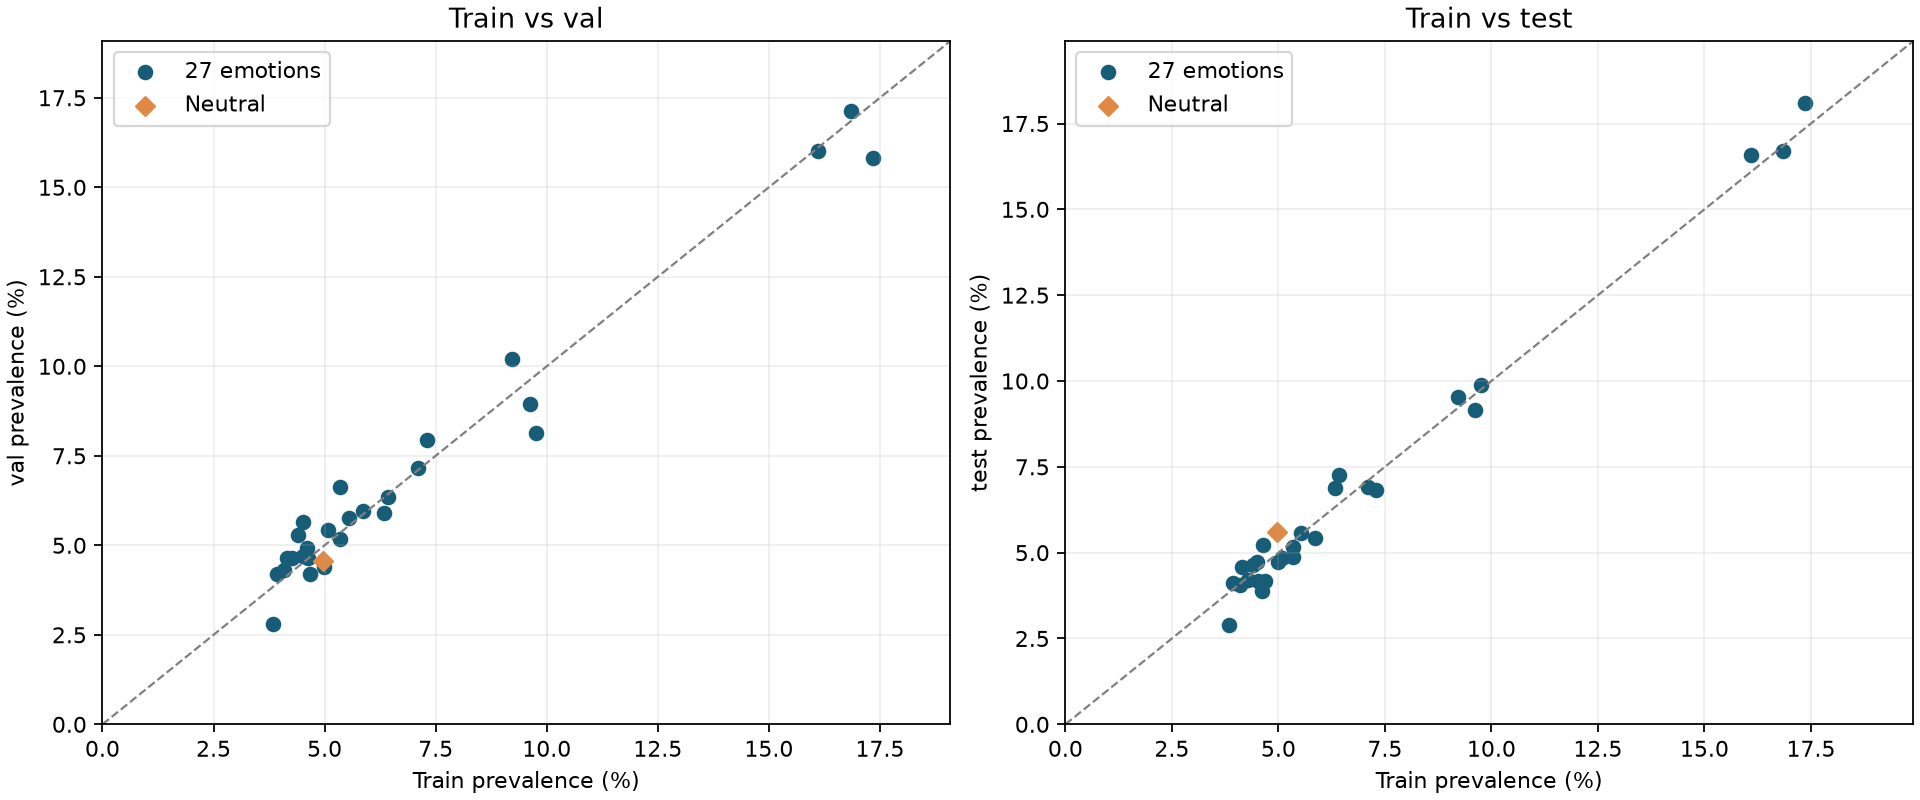

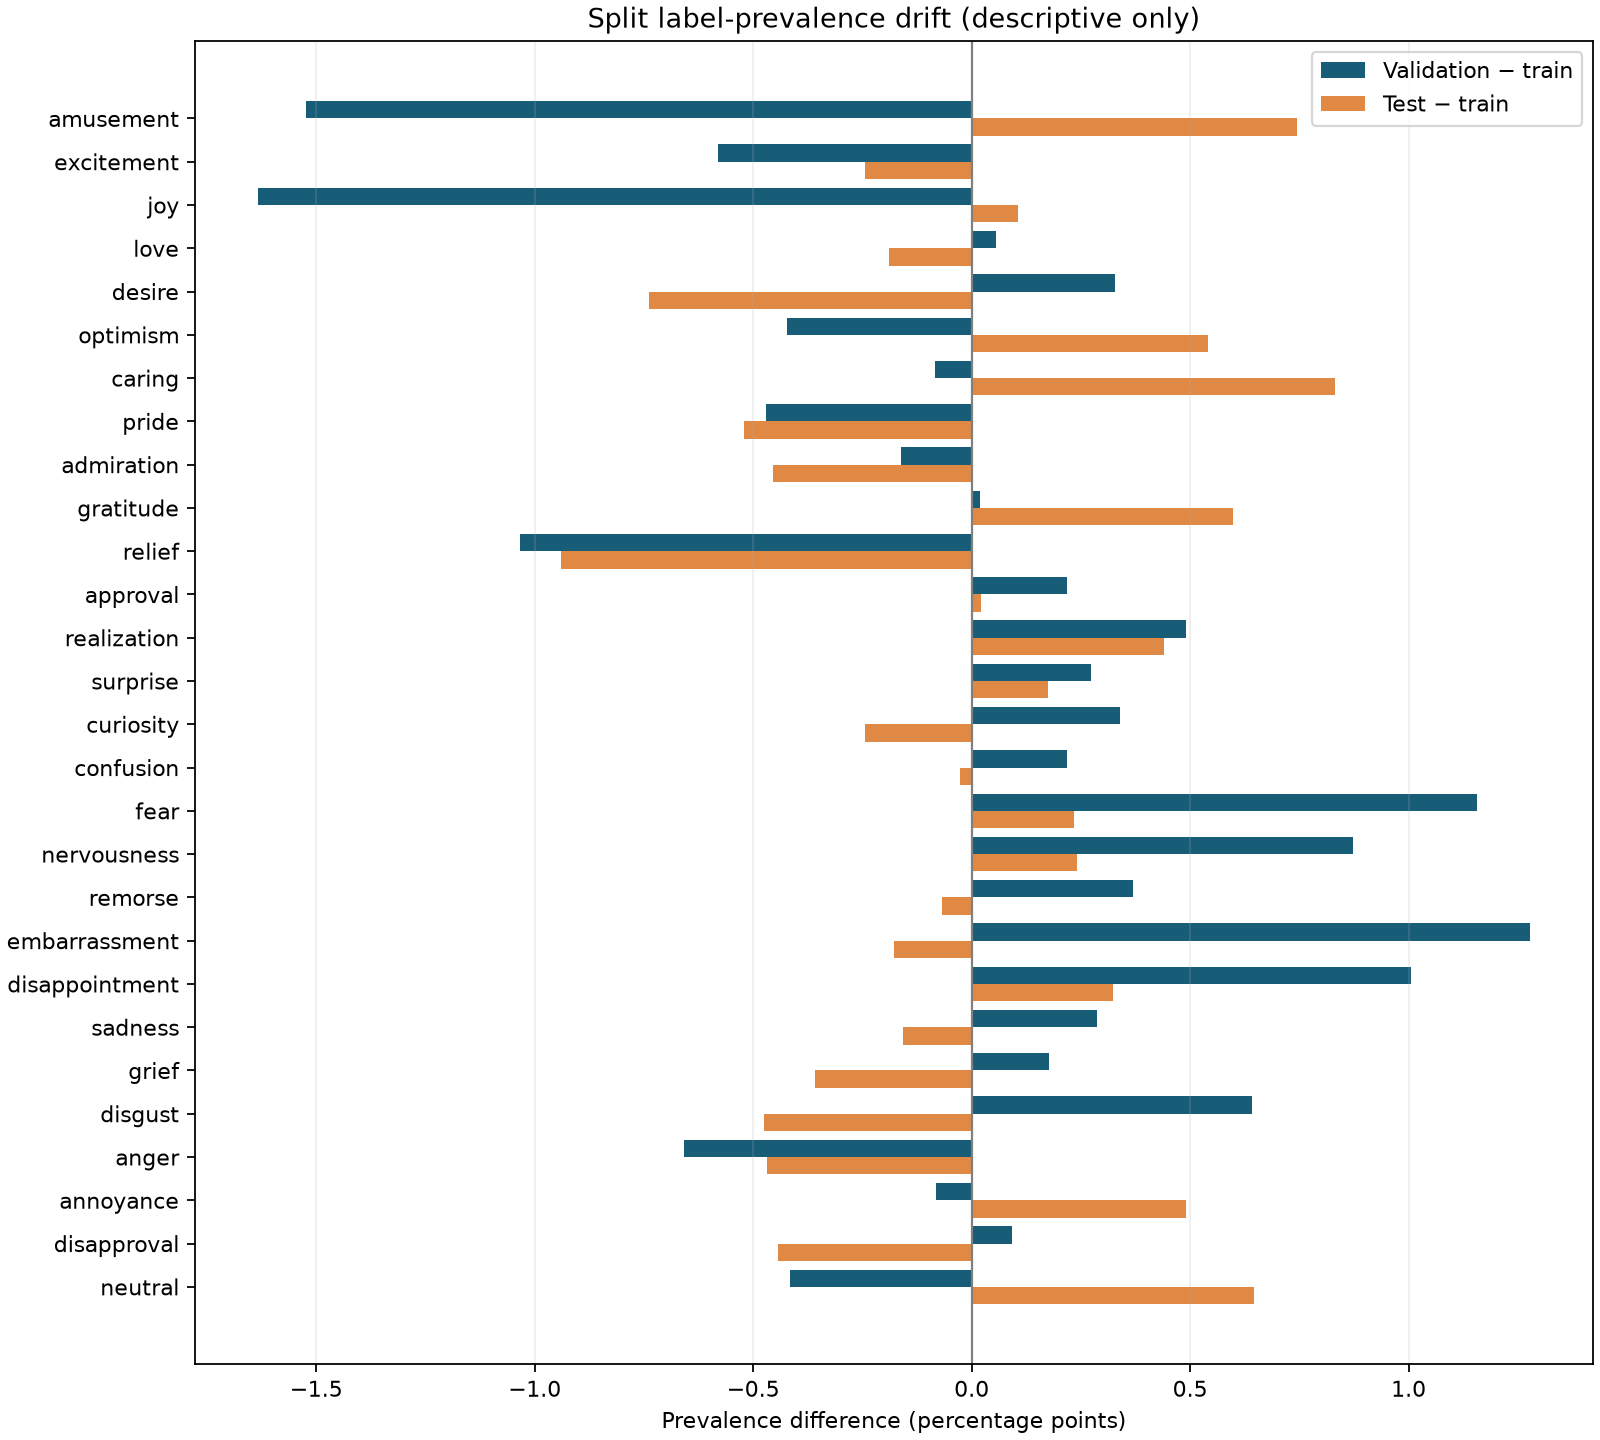

In [4]:
frequency = frequency_table(Y28)
display(frequency.round(6))
missing_labels = pd.DataFrame([dict(split=split, zero_support_labels=';'.join(
    LABELS28[j] for j, count in enumerate(Y28[split].sum(axis=0)) if count == 0)) for split in SPLITS])
display(missing_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, split in zip(axes, ('val', 'test')):
    ax.scatter(100 * frequency.train_prevalence.iloc[:27], 100 * frequency[f'{split}_prevalence'].iloc[:27],
               label='27 emotions', color='#185d78')
    ax.scatter(100 * frequency.train_prevalence.iloc[27], 100 * frequency[f'{split}_prevalence'].iloc[27],
               marker='D', color='#df8944', label='Neutral')
    limit = 1.1 * 100 * max(frequency.train_prevalence.max(), frequency[f'{split}_prevalence'].max())
    ax.plot([0, limit], [0, limit], '--', color='gray', linewidth=1)
    ax.set(xlabel='Train prevalence (%)', ylabel=f'{split} prevalence (%)', title=f'Train vs {split}',
           xlim=(0, limit), ylim=(0, limit))
    ax.legend(); ax.grid(alpha=.2)
fig.savefig(OUT/'label_prevalence.png', dpi=160)
plt.close(fig)
display(Image(filename=str(OUT/'label_prevalence.png')))

fig, ax = plt.subplots(figsize=(10, 9), constrained_layout=True)
positions = np.arange(28)
ax.barh(positions - .2, frequency.val_drift_pp, height=.4, label='Validation − train', color='#185d78')
ax.barh(positions + .2, frequency.test_drift_pp, height=.4, label='Test − train', color='#df8944')
ax.axvline(0, color='gray', linewidth=1)
ax.set(yticks=positions, yticklabels=LABELS28, xlabel='Prevalence difference (percentage points)',
       title='Split label-prevalence drift (descriptive only)')
ax.invert_yaxis(); ax.legend(); ax.grid(axis='x', alpha=.2)
fig.savefig(OUT/'label_drift.png', dpi=160)
plt.close(fig)
display(Image(filename=str(OUT/'label_drift.png')))

## 5. Cardinality và Neutral

Giữ hai phép đếm riêng: 27 cảm xúc bỏ Neutral; 28 nhãn tính cả Neutral. Ví dụ `[27]` có cardinality 0/1 và `[2,27]` có cardinality 1/2. Total variation (TV) giữa hai phân bố là `0.5 × sum(abs(p−q))`, nằm trong [0,1]; nhỏ hơn nghĩa là hai histogram gần nhau hơn, không chứng minh cách tạo split.

,encoding,split,cardinality,count,proportion
0,emotion27,train,0,570,0.034483
1,emotion27,train,1,5075,0.307018
2,emotion27,train,2,7527,0.455354
3,emotion27,train,3,2879,0.174168
4,emotion27,train,4,438,0.026497
5,emotion27,train,5,41,0.002480
6,emotion27,val,0,75,0.036302
7,emotion27,val,1,622,0.301065
8,emotion27,val,2,927,0.448693
9,emotion27,val,3,387,0.187318


,encoding,heldout,total_variation_vs_train
0,emotion27,val,0.015877
1,emotion27,test,0.011719
2,labels28,val,0.012525
3,labels28,test,0.010695


,split,neutral_only,mixed_neutral,emotion_only
0,train,570,251,15709
1,val,75,19,1972
2,test,80,36,1951


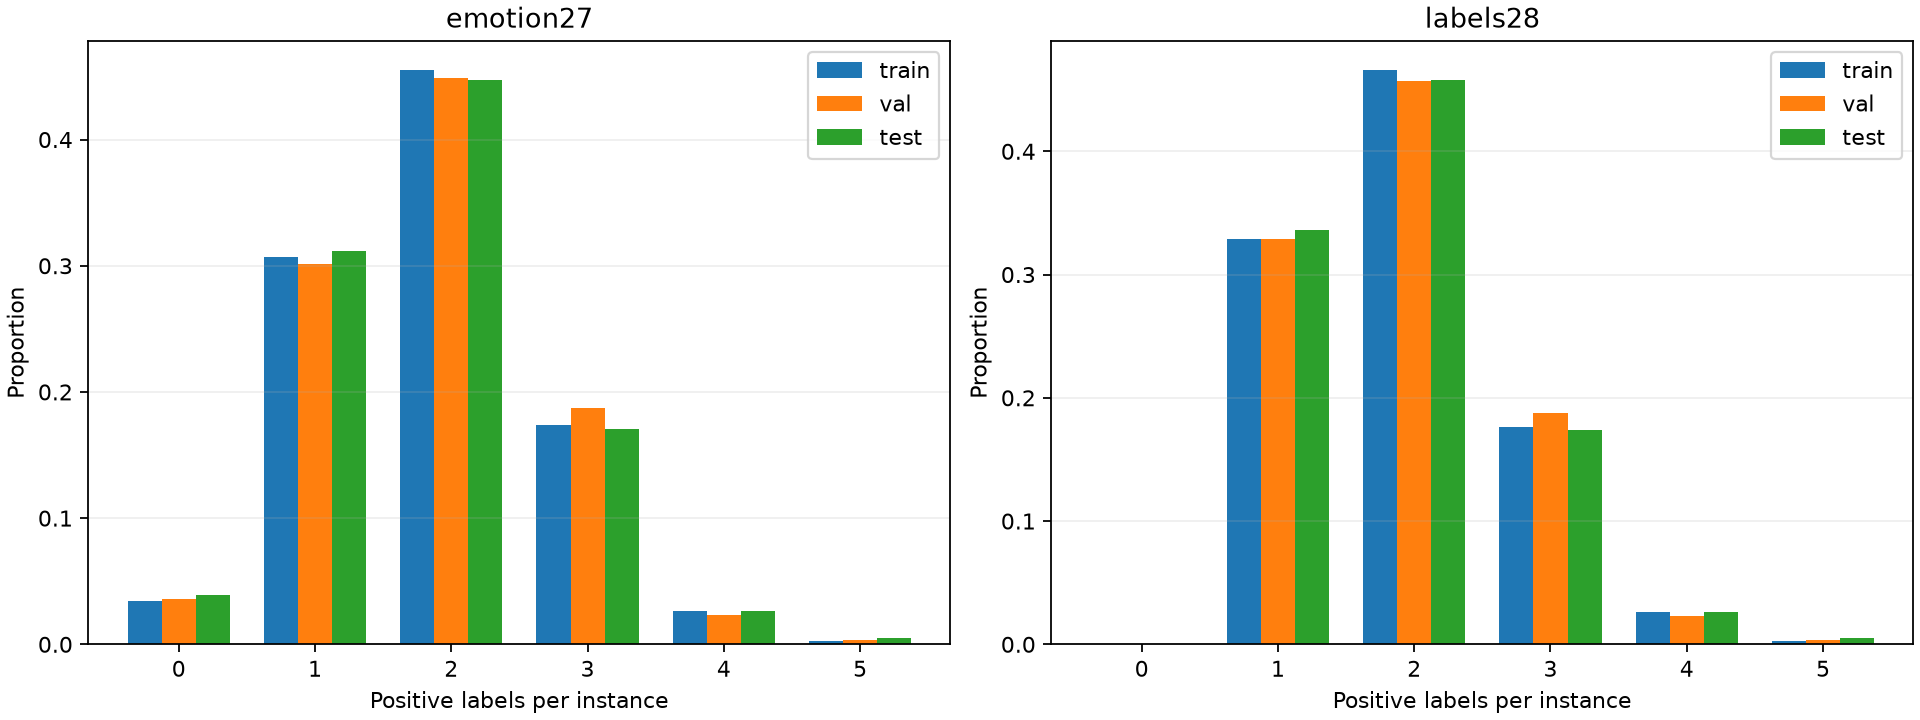

In [5]:
cardinality_rows, distance_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, (encoding, matrices) in zip(axes, [('emotion27', Y27), ('labels28', Y28)]):
    maximum = max(int(y.sum(axis=1).max()) for y in matrices.values())
    distributions = {split: cardinality_distribution(y, maximum) for split, y in matrices.items()}
    for offset, split in enumerate(SPLITS):
        card = matrices[split].sum(axis=1)
        for k, proportion in enumerate(distributions[split]):
            cardinality_rows.append(dict(encoding=encoding, split=split, cardinality=k,
                                         count=int((card == k).sum()), proportion=float(proportion)))
        ax.bar(np.arange(maximum+1) + (offset-1)*.25, distributions[split], width=.25, label=split)
    for split in ('val', 'test'):
        distance_rows.append(dict(encoding=encoding, heldout=split,
                                  total_variation_vs_train=total_variation(distributions['train'], distributions[split])))
    ax.set(xticks=range(maximum+1), xlabel='Positive labels per instance', ylabel='Proportion', title=encoding)
    ax.legend(); ax.grid(axis='y', alpha=.2)
cardinality = pd.DataFrame(cardinality_rows)
distances = pd.DataFrame(distance_rows)
display(cardinality.round(6))
display(distances.round(6))
display(split_summary[['split', 'neutral_only', 'mixed_neutral', 'emotion_only']])
fig.savefig(OUT/'cardinality.png', dpi=160)
plt.close(fig)
display(Image(filename=str(OUT/'cardinality.png')))

## 6. Cặp nhãn — chọn từ train, đối chiếu validation

Chọn 10 cặp cảm xúc có số cùng dương lớn nhất ở train; không chọn lại dựa trên validation. So sánh **joint prevalence** (cùng dương / tổng số mẫu của split), không so count thô. Đây không phải đánh giá dependency của mô hình và không tạo ma trận quan hệ nhãn từ test labels.

,label_a,label_b,train_count,val_count,train_joint_prevalence,val_joint_prevalence,val_drift_pp
0,disappointment,sadness,904,122,0.054688,0.059051,0.436286
1,anger,annoyance,699,77,0.042287,0.037270,-0.501666
2,sadness,grief,620,81,0.037508,0.039206,0.169863
3,amusement,joy,568,48,0.034362,0.023233,-1.112847
4,annoyance,disapproval,469,67,0.028373,0.032430,0.405716
5,joy,love,395,50,0.023896,0.024201,0.030541
6,disgust,anger,379,49,0.022928,0.023717,0.078932
7,embarrassment,sadness,366,48,0.022142,0.023233,0.109174
8,excitement,joy,359,34,0.021718,0.016457,-0.526117
9,amusement,annoyance,336,40,0.020327,0.019361,-0.096559


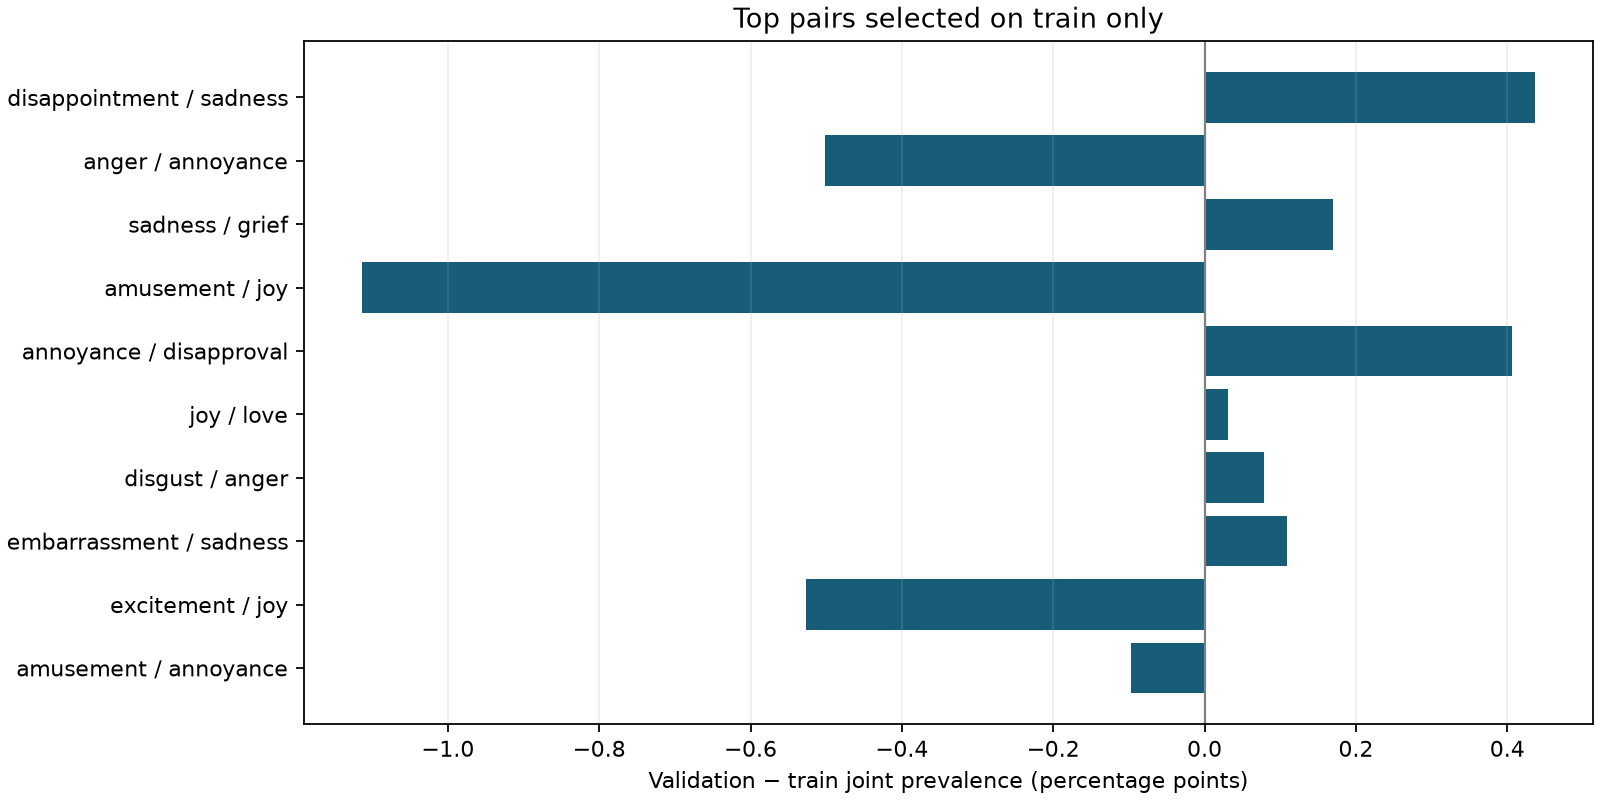

In [6]:
train_y, val_y = Y27['train'], Y27['val']
train_co = train_y.T @ train_y
selected_pairs = sorted(itertools.combinations(range(27), 2),
                        key=lambda pair: (-int(train_co[pair[0], pair[1]]), pair[0], pair[1]))[:TOP_PAIRS]
pair_rows = []
for a, b in selected_pairs:
    train_count = int(train_co[a, b])
    val_count = int((val_y[:, a] * val_y[:, b]).sum())
    pair_rows.append(dict(label_a=LABELS[a], label_b=LABELS[b], train_count=train_count,
        val_count=val_count, train_joint_prevalence=train_count/len(train_y),
        val_joint_prevalence=val_count/len(val_y),
        val_drift_pp=100*(val_count/len(val_y)-train_count/len(train_y))))
pairs = pd.DataFrame(pair_rows)
display(pairs.round(6))
assert not any('test' in column for column in pairs.columns)
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(pairs.label_a + ' / ' + pairs.label_b, pairs.val_drift_pp, color='#185d78')
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='Validation − train joint prevalence (percentage points)', title='Top pairs selected on train only')
ax.invert_yaxis(); ax.grid(axis='x', alpha=.2)
fig.savefig(OUT/'train_selected_pairs_validation.png', dpi=160)
plt.close(fig)
display(Image(filename=str(OUT/'train_selected_pairs_validation.png')))

## 7. Lưu bằng chứng và kết luận từ số liệu thật

Kết luận tách riêng **toàn vẹn dữ liệu** và **chẩn đoán phân bố**. Không phát biểu “đã chứng minh stratified” hoặc “không có khác biệt thống kê”. File README tạo từ kết quả thật có thể trích vào báo cáo; provenance ghi checksum nguồn và fixed IDs để đối chiếu lượt chạy. Mọi CSV/ảnh xuất ra đều không có text nguồn.

In [7]:
after_hashes = {str(p.relative_to(ROOT)): sha256(p) for p in protected_files}
assert before_hashes == after_hashes, 'CSV nguồn và fixed split IDs phải giữ nguyên.'
integrity.loc[len(integrity)] = dict(check='Source CSV/fixed ID files unchanged', passed=True, observed=1)
integrity_ok = bool(integrity.passed.all())
metrics = {}
for scope, subset in [('emotion27', frequency.iloc[:27]), ('labels28', frequency)]:
    for split in ('val', 'test'):
        column = f'{split}_drift_pp'
        row = subset.loc[subset[column].abs().idxmax()]
        metrics[f'{scope}_{split}_max_abs_drift_pp'] = float(abs(row[column]))
        metrics[f'{scope}_{split}_max_drift_label'] = str(row.label)

summary = dict(integrity_status='PASS' if integrity_ok else 'FAIL',
    distribution_status='DESCRIPTIVE_ONLY', generating_algorithm='UNVERIFIED',
    effective_split_sizes={s: len(f) for s, f in frames.items()}, excluded_train_rows=len(excluded),
    per_label_drift=metrics, cardinality_total_variation=distances.to_dict('records'),
    missing_labels=missing_labels.to_dict('records'), top_pairs_selection='Train only; ID tie-break; validation comparison only',
    limitations=['No proof of original stratification algorithm', 'No post-hoc distribution pass threshold',
                 'No model/threshold tuning; no test co-occurrence matrix', 'No raw text exported'])

exports = {'split_summary.csv': split_summary, 'leakage_audit.csv': leakage,
    'integrity_checks.csv': integrity, 'label_prevalence.csv': frequency,
    'missing_label_coverage.csv': missing_labels, 'cardinality_distribution.csv': cardinality,
    'cardinality_total_variation.csv': distances, 'train_selected_pairs_validation.csv': pairs,
    'excluded_train_ids.csv': excluded[['id']]}
for name, table in exports.items():
    assert not {'text', 'normalized'} & set(table.columns)
    table.to_csv(OUT/name, index=False)

provenance = dict(source_data_sha256={s: before_hashes[f'data/{s}.csv'] for s in SPLITS},
    fixed_split_files_sha256={k: v for k, v in before_hashes.items() if k.startswith('splits/')},
    effective_ordered_ids_sha256={s: hashlib.sha256(chr(10).join(f.id).encode()).hexdigest() for s, f in frames.items()},
    source_files_unchanged=True, python=platform.python_version(), platform=platform.platform(),
    packages={name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'scikit-learn')},
    normalization='NFC + whitespace collapse; common.load_data drops train overlaps with heldout',
    label_order=LABELS28, random_operations=False, model_training=False,
    test_use='Descriptive marginal prevalence/cardinality only; no test pair matrix/model selection',
    generated_by='notebooks/07_split_distribution_audit.ipynb')
(OUT/'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2)+chr(10), encoding='utf-8')
(OUT/'provenance.json').write_text(json.dumps(provenance, ensure_ascii=False, indent=2)+chr(10), encoding='utf-8')

val_gap = metrics['emotion27_val_max_abs_drift_pp']
test_gap = metrics['emotion27_test_max_abs_drift_pp']
val_label = metrics['emotion27_val_max_drift_label']
test_label = metrics['emotion27_test_max_drift_label']
neutral = frequency.iloc[27]
conclusion = f'''# Audit split ViGoEmotions — bằng chứng phân bố

Trạng thái toàn vẹn: **{summary['integrity_status']}**. Train/validation/test thực nghiệm: **{len(frames['train'])} / {len(frames['val'])} / {len(frames['test'])}**. Loại {len(excluded)} mẫu train trùng heldout theo pipeline; không sửa CSV nguồn hoặc fixed split IDs. Các kiểm tra cụ thể ở `integrity_checks.csv` và `leakage_audit.csv`.

Trên 27 cảm xúc, chênh lệch prevalence tuyệt đối lớn nhất so với train: validation **{val_gap:.4f} điểm phần trăm** ({val_label}); test **{test_gap:.4f} điểm phần trăm** ({test_label}). Đây là tỷ lệ nhãn dương trên số mẫu, không phải chênh lệch count thô. Đọc thêm mức biến động tương đối và support trong `label_prevalence.csv`.

Neutral có {int(neutral.train_count)} / {int(neutral.val_count)} / {int(neutral.test_count)} mẫu dương trên train/val/test; gồm Neutral-only và mixed, không coi mixed là Neutral-only. Cardinality theo cả hai cách mã hóa ở `cardinality_distribution.csv`; khoảng cách TV ở `cardinality_total_variation.csv`. Cặp nhãn được chọn trên train, chỉ đối chiếu validation trong `train_selected_pairs_validation.csv`; không tạo ma trận nhãn test.

**Diễn giải dùng trong báo cáo:** Nhóm giữ split được cấp, kiểm tra toàn vẹn và định lượng độ lệch phân bố đa nhãn bằng notebook audit tái chạy được. Những bảng này là bằng chứng về chất lượng phân bố, không xác nhận thuật toán tạo split gốc là iterative stratification. Không dùng điểm mô hình/test để lựa chọn hoặc đổi split. Mức chấp nhận phân bố và việc dùng split được cấp cần đối chiếu yêu cầu giảng viên; notebook không tự gán chứng nhận “đạt stratification”.

**Tái chạy:** mở `notebooks/07_split_distribution_audit.ipynb`, kernel project, Run All. Output mặc định tại `reports/split_audit/`. Không train mô hình hoặc tải dependency qua mạng. Chỉ có thống kê tổng hợp, ID và metadata; không có bình luận nguồn. Kết quả là chẩn đoán mô tả; không dùng ngưỡng phân bố đặt sau khi xem số liệu để công bố PASS.

Nguồn yêu cầu: `docs/02-vigoemotions-vietnamese-emotion.pdf` (Midterm A; Reproducibility Rules), `docs/student-guide.pdf` (Midterm; Submission Package). `provenance.json` lưu môi trường và checksum. Các file ở đây độc lập với bảng baseline và báo cáo midterm hiện hữu.
'''
(OUT/'README.md').write_text(conclusion, encoding='utf-8')
display(Markdown(conclusion))
print('Đã xuất', len(exports), 'CSV, 4 biểu đồ, summary.json, provenance.json và README.md.')
assert integrity_ok, 'Có lỗi toàn vẹn: đọc integrity_checks.csv; không tự đổi split để che lỗi.'

# Audit split ViGoEmotions — bằng chứng phân bố

Trạng thái toàn vẹn: **PASS**. Train/validation/test thực nghiệm: **16530 / 2066 / 2067**. Loại 1 mẫu train trùng heldout theo pipeline; không sửa CSV nguồn hoặc fixed split IDs. Các kiểm tra cụ thể ở `integrity_checks.csv` và `leakage_audit.csv`.

Trên 27 cảm xúc, chênh lệch prevalence tuyệt đối lớn nhất so với train: validation **1.6324 điểm phần trăm** (joy); test **0.9387 điểm phần trăm** (relief). Đây là tỷ lệ nhãn dương trên số mẫu, không phải chênh lệch count thô. Đọc thêm mức biến động tương đối và support trong `label_prevalence.csv`.

Neutral có 821 / 94 / 116 mẫu dương trên train/val/test; gồm Neutral-only và mixed, không coi mixed là Neutral-only. Cardinality theo cả hai cách mã hóa ở `cardinality_distribution.csv`; khoảng cách TV ở `cardinality_total_variation.csv`. Cặp nhãn được chọn trên train, chỉ đối chiếu validation trong `train_selected_pairs_validation.csv`; không tạo ma trận nhãn test.

**Diễn giải dùng trong báo cáo:** Nhóm giữ split được cấp, kiểm tra toàn vẹn và định lượng độ lệch phân bố đa nhãn bằng notebook audit tái chạy được. Những bảng này là bằng chứng về chất lượng phân bố, không xác nhận thuật toán tạo split gốc là iterative stratification. Không dùng điểm mô hình/test để lựa chọn hoặc đổi split. Mức chấp nhận phân bố và việc dùng split được cấp cần đối chiếu yêu cầu giảng viên; notebook không tự gán chứng nhận “đạt stratification”.

**Tái chạy:** mở `notebooks/07_split_distribution_audit.ipynb`, kernel project, Run All. Output mặc định tại `reports/split_audit/`. Không train mô hình hoặc tải dependency qua mạng. Chỉ có thống kê tổng hợp, ID và metadata; không có bình luận nguồn. Kết quả là chẩn đoán mô tả; không dùng ngưỡng phân bố đặt sau khi xem số liệu để công bố PASS.

Nguồn yêu cầu: `docs/02-vigoemotions-vietnamese-emotion.pdf` (Midterm A; Reproducibility Rules), `docs/student-guide.pdf` (Midterm; Submission Package). `provenance.json` lưu môi trường và checksum. Các file ở đây độc lập với bảng baseline và báo cáo midterm hiện hữu.


Đã xuất 9 CSV, 4 biểu đồ, summary.json, provenance.json và README.md.
